<div style="border:solid green 2px; padding: 20px">
    
<b>Николай, привет!</b> Мы рады тебя видеть на территории код-ревьюеров 😎. Ты проделал большую работу над проектом, но давай познакомимся и сделаем его еще лучше! У нас тут своя атмосфера и несколько правил:


1. Меня зовут Александр Матвеевский. Я работаю код-ревьюером, моя основная цель — не указать на совершенные тобою ошибки, а поделиться своим опытом и помочь тебе стать дата-специалистом.
2. Общаемся на ты.
3. Если хочешь написать, спросить - не нужно стесняться. Только выбери свой цвет для комментария.  
4. Это учебный проект, тут можно не бояться сделать ошибку.  
5. У нас с тобой 6 попыток для сдачи проекта.  
6. Let's Go!

---

Я буду красить комментарии цветом, пожалуйста, не удаляй их:

<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__

Такой комментарий нужно исправить обязательно, он критически влияет на удачное выполнение проекта.
</div>
    
---

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__


Такой комментарий является рекомендацией или советом. Можешь использовать их на своё усмотрение.
</div>

---

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Такой комментарий  говорит о том, что было сделано что-то качественное и правильное =)
</div>
    
---
    
Предлагаю работать над проектом в диалоге: если ты что-то меняешь в проекте или отвечаешь на мои комментарии — пиши об этом. Мне будет легче отследить изменения, если ты выделишь свои комментарии:   
    
<div class="alert alert-info"> <b>Комментарии студента:</b> Например, вот так.</div>
    
Всё это поможет выполнить повторную проверку твоего проекта оперативнее. Если будут какие-нибудь вопросы по моим комментариям, пиши, будем разбираться вместе :)    
    
---

# Эксперименты с нейросетями: анализ тональности текста

Вы работаете в команде картографического сервиса YouMap, который собирает отзывы о компаниях, организациях, квартирах и других заведениях из разных источников. Команде качества нужно научиться автоматически находить негативные сообщения и передавать их на приоритетную обработку. Ваша задача — подготовить данные, обучить модель и объяснить, какой подход лучше помогает находить негативные отзывы.

Вам предстоит использовать датасет `ds_s26_geo_reviews.csv`.

|Признак|Описание|Комментарий|
|:---|:---|:---|
|text|Текст отзыва|Отзывы для обучения нейросети|
|address|Адрес организации|Только для EDA|
|federal_district|Федеральный округ|Категориальный признак|
|name_ru|Название организации|Только для EDA. <br> Не используйте его для обучения|
|rubrics|Категории, к которым относится организация|Только для EDA|
|rubrics_count|Количество категорий, к которым относится организация|Числовой признак|
|review_len_chars|Длина отзыва в символах|Числовой признак|
|review_len_words|Длина отзыва в словах|Числовой признак|
|emoji_count|Количество эмодзи в отзыве|Числовой признак|
|target|1 — негативный отзыв, оценка 1–2. <br> 0 — остальные отзывы, оценка 3–5.|Целевая переменная|

В проекте вы сравните два способа представить один и тот же текст для нейросети:

*   Числовые признаки текста + MLP.
*   Индексы токенов + эмбеддинги + mean pool +  MLP.

Основная метрика — PR-AUC, вспомогательные — ROC-AUC, precision, recall, F1-мера.

В ячейках с пропусками (`...`) допишите недостающий код. Не меняйте названия ключевых переменных: они используются в следующих блоках.

## Шаг 1. Импорт библиотек, настройка констант, обеспечение воспроизводимости

Удаляем временный файл requirements и создаем новый по зависимостям из ноутбука:

In [2]:
! rm -f requirements.txt
! python --version

Python 3.12.9


Установим необходимые библиотеки:

In [3]:
from pathlib import Path

requirements_file = Path('requirements.txt')
requirements = [
    'torch==2.9.1',
    'torchvision==0.24.1',
    'pandas==2.1.4',
    'seaborn==0.13.2',
    'scikit-learn==1.4.2',
    'requests==2.32.3',
    'humanfriendly==10.0',
]
if not requirements_file.exists():
    with open(requirements_file, 'w') as f:
        f.write('\n'.join(requirements))
        print(f'{requirements_file} created')
else:
    print(f'{requirements_file} exists')

print('Установка зависимостей...')
!pip install -r requirements.txt
print('Зависимости успешно установлены!')

requirements.txt created
Установка зависимостей...
Зависимости успешно установлены!


In [4]:
from pathlib import Path
from collections import Counter
import random
import re
import os
import string
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    precision_recall_fscore_support,
    roc_auc_score,
)

from IPython.display import display
from humanfriendly import format_size

Объявляем утилитарные классы:

In [5]:
TARGET_COL_NAME = 'late_delivery_risk'
RANDOM_STATE = 42
NAN_FLOAT = -999999.0
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', None) # выводить все колонки
pd.set_option('display.max_colwidth', 500) # выводить больше символов в ячейке


#### Заргузка ресурсов
class ResourceLoader:
    """
    Класс для безопасной загрузки ресурсов по http или с помощью подключения к БД.
    По http можно загружать как датасет в формате CSV, так и прозвольный файл.
    Если файл уже был скачан ранее и сохранен в локальной файловой системе, то
    загрузка из удаленного источника не производится.

    Для загрузки датасета: load_dataset(dataset_url, local_file, local_path='datasets'): dataframe
    Для загрузки файла: load_resource(resource_url, local_path, local_file): path
    """

    def __init__(self):
        pass

    def load_resource(self, resource_url, local_path, local_file):
        """
        Загрузка произвольного файла из сети и сохраение его локально.
        Если файл уже существует локально, то загрузка не происходит
        """
        local_resource_file = f'{local_path}/{local_file}'
        if os.path.exists(local_resource_file):
            print(f'Файл {local_resource_file} уже существует')
            return local_resource_file

        os.makedirs(local_path, exist_ok=True)
        print(f'Загружаем файл из {resource_url}')
        response = requests.get(resource_url)
        if response.status_code == 200:
            with open(local_resource_file, 'wb') as f:
                f.write(response.content)
            file_size = format_size(os.path.getsize(local_resource_file))
            print(f'Файл успешно загружен в {local_resource_file},',
                  f'размер файла: {file_size}')
            return local_resource_file
        else:
            raise ValueError(f'Ошибка при загрузке файла: {response.status_code}')


    def load_dataset(
        self,
        dataset_url,
        local_file = None,
        local_path='datasets',
        sep=',',
        decimal='.'
    ):
        """
        Специальный. метод загрузки датасета по сети. Если датасет уже был скачан ранее и
        сохранен в локальной файловой системе, то загрузка не происходит.

        Parameters:
            dataset_url: str - url датасета
            local_file: str - имя файла, куда будет сохранен датасет (если None - будет вычислен из URL)
            local_path: str - путь к папке, куда будет сохранен датасет
            sep: str - разделитель в файле CSV
            decimal: str - символ, разделяющий целую часть от дробной в CSV

        Returns:
            df: pd.DataFrame - датасет
        """
        if local_file is None:
            local_file = dataset_url.split('/')[-1]
        local_dataset_file = f'{local_path}/{local_file}'
        remote_dataset_url = dataset_url
        def read_dataset_csv():
            return pd.read_csv(local_dataset_file, sep=sep, decimal=decimal)

        try:
            df = read_dataset_csv()
            print(f'Датасет успешно загружен из {local_dataset_file}')
        except FileNotFoundError:
            self.load_resource(remote_dataset_url, local_path, local_file)
            df = read_dataset_csv()

        print(f'Размер загруженного датасета: {df.shape[0]} строк, {df.shape[1]} столбцов', )
        return df

#### EDA
class CorrelationDisplayer:
    """
    Класс для отображения матрицы корреляций признаков в разных видах
    """
    def __init__(self, corr_matrix):
        self.corr_matrix = corr_matrix

    def get_corr_matrix(self):
        """
        Возвращает матрицу корреляций признаков, переданную в конструкторе
        """
        return self.corr_matrix

    def _subset_corr_matrix(self, subset):
        subset_cols = self.corr_matrix.columns if subset is None else subset
        return self.corr_matrix.loc[subset_cols, subset_cols]

    def draw_corr_matrix_full(
        self,
        digits=2,
        title='Матрица корреляций признаков',
        subtitle=None,
        figsize=(16, 10),
        subset=None,
    ):
        """
        Отображает полную матрицу корреляций признаков в виде heatmap

        Parameters:
            digits: int - количество знаков после запятой в значениях heatmap
            subset: [] - модмножество столбцов кор.матрицы для отображения
        """
        plt.subplots(figsize=figsize)
        matrix = self._subset_corr_matrix(subset)
        sns.heatmap(matrix, fmt=f'.{digits}f', annot=True, cmap='coolwarm', linewidths=0.5)
        plt.title(title + "\n" + subtitle if subtitle else title)
        plt.show()


    def draw_corr_matrix_with_target(
            self,
            target_col,
            title='Матрица корреляций с таргетом',
            subtitle=None,
            figsize=(16, 10),
    ):
        """
        Отображает матрицу корреляций признаков с таргетом в виде вертикального heatmap

        Parameters:
            target_col: str - название столбца таргета
            title: str - заголовок графика
            subtitle: str - подзаголовок графика
        """
        plt.subplots(figsize=figsize)
        data_heatmap = self.corr_matrix.loc[
            self.corr_matrix.index != target_col
        ][[target_col]].sort_values(by=target_col, ascending=False)
        sns.heatmap(data_heatmap, annot=True, cmap='coolwarm', linewidths=0.5)
        plt.title(title + "\n" + subtitle if subtitle else title)
        plt.show()

    def draw_pair_correlations(self, subset=None, figsize=(16, 10), corr_threshold=0.9):
        """
        Отображает попарные корреляции признаков в виде вертикального heatmap

        Parameters:
            subset: [] - модмножество столбцов кор.матрицы для отображения
            figsize: (int, int) - размер графика
            corr_threshold: float - порог корреляции, ниже которого корреляция не будет отображена
        """
        # преобразуем матрицу корреляции в датафрейм попарных корреляций
        # feature_1+feature_2 -> correlation
        matrix = self._subset_corr_matrix(subset)
        pair_correlations = matrix \
            .stack() \
            .reset_index() \
            .rename(columns={
                'level_0': 'feature1',
                'level_1': 'feature2',
                0: 'correlation'
            }) \
            .query('feature1 != feature2') \
            .sort_values(by='correlation', ascending=False) \

        def order_pair(row):
            if row['feature1'] > row['feature2']:
                return row['feature2'] + '/' + row['feature1']
            else:
                return row['feature1'] + '/' + row['feature2']

        pair_correlations['order_pair'] = pair_correlations.apply(order_pair, axis=1)
        pair_correlations = pair_correlations.drop(columns=['feature1', 'feature2'])
        pair_correlations = pair_correlations.drop_duplicates().reset_index(drop=True)
        pair_correlations = pair_correlations.query('correlation > @corr_threshold')
        pair_correlations = pair_correlations.sort_values(by='correlation')
        pair_correlations.plot(
            x='order_pair',
            y='correlation',
            xlabel='Значение корреляции',
            ylabel='Пара признаков',
            kind='barh',
            legend=False,
            figsize=figsize,
            grid=True,
        )
        plt.title('Попарные корреляции')
        plt.show()
        return pair_correlations.sort_values(by='correlation', ascending=False).reset_index(drop=True)

class EDAHelper:
    """
    Класс для выполнения Exploratory Data Analysis (EDA)
    """
    def __init__(self):
        pass

    def df_info(self, df, name = '', n_samples=3):
        """
        Выводит информацию о датасете:
        - количество строк и столбцов
        - размер датасета в памяти
        - первые, случайные и последние n_samples строк
        - информацию о типах данных столбцов
        - информацию о пропущенных значениях и проценте пропущенных значений в каждом столбце

        Parameters:
            df: pd.DataFrame - датафрейм
            name: str - произвольное название датасета
            n_samples: int - количество строк для вывода объектов датасета из начала, середины и конца
        """
        print('-'*50)
        print(f'Описание датасета {name}:')
        print(f'Датасет {name} содержит {df.shape[0]} строк и {df.shape[1]} столбцов.')
        print(f'Размер датасета {name} в памяти: {format_size(df.memory_usage().sum())}')
        print('-'*50)
        print(f'Данные датасета {name}:')
        print('-'*50)
        sample_df =  pd.concat([
            df.head(n_samples).assign(place='head'),
            df.sample(n_samples, random_state=RANDOM_STATE).assign(place='random'),
            df.tail(n_samples).assign(place='tail'),
        ]).sort_index()
        # move place column to first place
        last_col = sample_df.pop(sample_df.columns[-1])
        sample_df.insert(0, last_col.name, last_col)
        display(sample_df)
        print('-'*50)

        print(df.info())
        nan_counts = self.na_info(df)
        if (len(nan_counts) > 0):
            display(nan_counts)
        else:
            print(f'В датасете {name} нет пропущенных значений')

    def convert_to_datetime(self, df, column, format='%Y-%m-%d', print_time_range=True):
        """
        Преобразует столбец в датафрейме в дату и отображает временную ось данных в столбце
        Parameters:
            df: pd.DataFrame - датафрейм
            column: str - название столбца
            format: str - формат даты
            print_time_range: bool - выводить ли временной диапазон данных в столбце
        """
        df[column] = pd.to_datetime(df[column], format=format)
        if print_time_range:
            self.print_time_range(df, column)
        return df


    def print_time_range(self, df, datetime_column):
        """
        Выводит временную ось данных в столбце
        Parameters:
            df: pd.DataFrame - датафрейм
            datetime_column: str - название столбца
        """
        # определим временную ось таблицы:
        start_date = df[datetime_column].min()
        end_date = df[datetime_column].max()
        diff = int((end_date - start_date) / np.timedelta64(1, 'D'))
        diff_years = diff / 365.25

        print(f'Данные в "{datetime_column}" представлены за период {diff} дн. ({diff_years:.1f} л.): {start_date} - {end_date}')

    def value_counts(self, df, column, normalize=False, title=None,
                 vertical=True, rot=0, hue=None, grid=True, show_data=True, figsize=None):
        """
        Выводит bar plot для каждого значения в столбце column,
        где размер графика зависит от количества объектов с данным значением
        Parameters:
            df: pd.DataFrame - датафрейм
            column: str - название столбца
            normalize: bool - нормализовать ли количество значений
            title: str - заголовок графика
            vertical: bool - вертикальный график
            rot: int - угол поворота подписей оси X
            hue: str - название столбца для группировки
            grid: bool - добавить ли сетку
            show_data: bool - выводить ли исходные данные
        """
        # --- Агрегация ---
        if hue:
            data = (
                df.groupby([column, hue])
                .size()
                .reset_index(name="count_or_share")
            )
            if normalize:
                total = data.groupby(hue)["count_or_share"].transform("sum")
                data["count_or_share"] = data["count_or_share"] / total
        else:
            data = (
                df[column]
                .value_counts(normalize=normalize)
                .rename("count_or_share")
                .reset_index()
            )

        # --- Сортировка для горизонтального графика ---
        if not vertical:
            if hue:
                order = (
                    data.groupby(column)["count_or_share"]
                    .sum()
                    .sort_values()
                    .index.tolist()
                )
            else:
                data = data.sort_values(by="count_or_share", ascending=False)
                order = None
        else:
            order = None

        # --- Подписи ---
        metric_label = "Доля внутри группы" if normalize else "Количество объектов"

        # --- Маппинг осей ---
        if hue:
            plot_axes = (
                {"x": column, "y": "count_or_share", "hue": hue}  # column на ось X, hue как цвет
                if vertical
                else {"x": "count_or_share", "y": column, "hue": hue}
            )
        else:
            plot_axes = (
                {"x": column, "y": "count_or_share"}
                if vertical
                else {"x": "count_or_share", "y": column}
            )

        # --- Визуализация ---
        with sns.axes_style("whitegrid" if grid else "white"):
            fig, ax = plt.subplots(figsize=figsize)
            sns.barplot(
                data=data,
                orient="v" if vertical else "h",
                ax=ax,
                order=order,
                **plot_axes,
            )

        ax.set_xlabel(column if vertical else metric_label)
        ax.set_ylabel(metric_label if vertical else column)
        ax.tick_params(axis="x" if vertical else "y", labelrotation=rot)
        ax.set_title(
            title if title
            else f'{"Доля" if normalize else "Количество"} значений {column}'
        )

        plt.tight_layout()
        plt.show()

        if show_data:
            display(data)



    def box_hist(self, df, column, title=None, bins='auto', hue=None, kde=True, stat='density'):
        """
        Выводит boxplot и histogramm для столбца датасета на одном графике
        Parameters:
            df: pd.DataFrame - датафрейм
            column: str - название столбца
            title: str - заголовок графика
            bins: int|'auto' - количество бинов в гистограмме
            hue: str - название столбца для разбивки гистограммы по категориям
            kde: bool - рисовать ли kernel density estimation (плотность распределения)
            stat: str - тип значения для оси Y:
                - 'density' - плотность распределения (Normalizes the bars so that the total area
                    of the histogram equals 1. This is ideal when comparing your histogram
                    to a continuous Probability Density
                - 'count' - количество объектов
                - 'frequency' - частота (Shows the number of observations divided by the bin width,
                    which accounts for bins of varying sizes)
                - 'probability' или 'proportion' - пропорция (Normalizes the counts so that the
                    height of all bars sums to 1. Useful for comparing relative contributions to a whole)
                - 'percent' - процент от всего датасета
        """
        f, (ax_box, ax_hist) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.15, .85)})
        display(pd.DataFrame(df[[column]].describe().T))
        sns.boxplot(df[column], orient='h', ax=ax_box)
        sns.histplot(data=df, x=column, ax=ax_hist, bins=bins, hue=hue, kde=kde, stat=stat)

        f.suptitle(f'Распределение признака {column}' if title is None else title)
        if stat == 'density':
            ylabel = 'Плотность распределения'
        elif stat == 'count':
            ylabel = 'Количество'
        elif stat == 'frequency':
            ylabel = 'Частота'
        elif stat == 'probability' or stat == 'proportion':
            ylabel = 'Доля'
        elif stat == 'percent':
            ylabel = 'Процент от общего числа'
        else:
            ylabel = 'Доля'

        ax_box.set(xlabel='')
        ax_hist.set(
            xlabel=f'Значения признака {column}',
            ylabel=ylabel
        )
        plt.show()

    def time_line(self, df, datetime_column, y_column, ylabel=None, plot_kwargs={}):
        """
        Выводит значение признака y_column на временной оси datetime_column
        Parameters:
            df: pd.DataFrame - датафрейм
            datetime_column: str - название столбца со временной осью
            y_column: str - название столбца для отображения по оси Y
            ylabel: str - подпись оси Y
        """
        if ylabel is None:
            ylabel = y_column

        params = {
            'kind': 'line',
            'x': datetime_column,
            'y': y_column,
            'xlabel': 'Дата',
            'ylabel': ylabel,
            'title': f'Завимость признака "{y_column}" от времени',
            'legend': False,
        } | plot_kwargs
        df.plot(
            **params
        )
        plt.show()

    def drop_duplicates(self, df, subset=None):
        """
        Удаляет дубликаты из датасета и иценивает их количество и процент от датасета
        Parameters:
            df: pd.DataFrame - датафрейм
            subset: list - список столбцов, по которым проверять дубликаты
        """
        ndups = df.duplicated(subset=subset).sum()
        print(f'Найдено {ndups} дубликатов по {"всем" if subset is None else subset} столбцам')
        if ndups > 0:
            df_orig = df.copy()
            df.drop_duplicates(subset=subset, inplace=True)
            diff = len(df_orig) - len(df)
            diff_pct = diff / len(df_orig) * 100
            print(f'Удалено {diff} строк ({diff_pct:.1f}%) из {len(df_orig)}')
        else:
            print('Дубликатов не обнаружено')

    def na_info(self, df, round_digits=1):
        '''
        Возвращает таблицу с количеством и процентом пропусков в столбцах датасета.
        '''
        count_na_name = 'Количество пропусков'
        res = pd.DataFrame({
            'Количество строк': len(df),
            count_na_name: df.isna().sum(),
            'Процент пропусков': round(df.isna().mean()*100, round_digits)
        }).sort_values(by=count_na_name, ascending=False)
        return res.query(f'`{count_na_name}` > 0').reset_index()


    # Уникальные значения всех категориальных признаков
    def get_unique_values(self, df, top_n=5, cat_columns=[]):
        """
        Возвращает таблицу с уникальными значениями всех категориальных признаков.
        Parameters:
            df: pd.DataFrame - датафрейм
            top_n: int - количество значений для вывода высококардинальных столбцов
            cat_columns: list - список категориальных признаков, если не передан,
            то берутся все категориальные признаки с типом object
        """
        print('Уникальные значения всех категориальных признаков:\n')
        data = []
        columns = cat_columns if cat_columns else df.select_dtypes(include=['object']).columns
        for col in columns:
            unique_vals = df[col].unique().tolist()
            unique_vals.sort()
            top_n_vals = ', '.join(unique_vals[:top_n])
            unique_val_str =  top_n_vals if len(unique_vals) <= top_n else f'{top_n_vals}, ...'
            num_of_unique_vals = df[col].nunique()
            data.append({
                'feature': col,
                'num_of_unique_vals': num_of_unique_vals,
                'unique_vals': unique_val_str,
            })
        return pd.DataFrame(data)

### Обучение модели
class ModelTrainHelper:
    """
    Класс с утилитарными функциями для обучения и оценки качества модели МО
    """
    def __init__(self):
        self.best_estimator_ = None
        pass

    def do_cross_validation(
            self,
            pipelines,
            X_train_val, y_train_val,
            scoring,
            metrics_df_list = [],
            return_train_score=False,
            cv=5,
    ):
        """
        Выполняет обучение модели с помощью кросс-валидации.
        Parameters:
            pipelines: dict - словарь с конфигурациями моделей {model_name: {'model': model, 'fit_params': fit_params}}
            X_train_val: pd.DataFrame - тренировочная выборка
            y_train_val: pd.Series - тренировочный таргет
            scoring: list - список метрик для оценки качества модели (первая метрика - главная)
            metrics_df_list: list - внешний параметр для сохранения результатов в сводную таблицу
        """
        cv_results_by_model = {}
        # Обучение моделей
        for name, p in pipelines.items():
            start_time = time.time()
            cv_results = cross_validate(
                estimator=p['model'],
                X=X_train_val,
                y=y_train_val,
                scoring=scoring,
                return_train_score=return_train_score,
                return_estimator=True,
                cv=cv,
                verbose=0,
                n_jobs=-1,
                params=p.get('fit_params'),
            )
            end_time = time.time()
            wall_time = end_time - start_time
            print(f'Обучение "{name}" заняло {wall_time:.2f} секунд')
            cv_results['wall_time_sec'] = wall_time
            cv_results_by_model[name] = cv_results

        def non_negative_metric_(metric):
            """
            Утилитарная функция для определения положительной или отрицательной метрики и ее имени
            по приставке neg_ в названии метрики
            """
            if metric.startswith('neg_'):
                return (True, metric[len('_neg'):])
            else:
                return (False, metric)

        is_neg_main_metric, main_metric = non_negative_metric_(scoring[0])

        # Сохранение результатов в сводную таблицу:
        def append_metrics_(result_metrics, model_name, cv_results, test_or_train='test', scoring=[]):
            """
            Утилитарная функция для усреднения результатов метрики, полученной на кросс-валидации
            и сохранения ее в сводную таблицу
            """
            metrics_dict = {}

            metrics_dict['model_name'] = model_name
            metrics_dict['wall_time_sec'] = cv_results.get('wall_time_sec', 0)
            metrics_dict = metrics_dict | {
                metric: np.mean(cv_results[f'{test_or_train}_{metric}']) for metric in scoring
            }
            # for metric in scoring:
            #     print(metric, cv_results[f'{test_or_train}_{metric}'])
            # add standard deviation
            # metrics_dict = metrics_dict | {
            #     f'{metric}_std': np.std(-cv_results[f'{test_or_train}_{metric}']) for metric in scoring
            # }

            keys = list(metrics_dict.keys())
            for metric in keys:
                # invert sign for neg metrics like neg_mean_squared_error
                # and rename metrics withoud neg
                if metric.startswith('neg_'):
                    metrics_dict[metric[len('neg_'):]] = metrics_dict[metric] * -1 if not metric.endswith('_std') else 1
                    metrics_dict.pop(metric)

            result_metrics.append(metrics_dict)
            return metrics_dict

        for model_name, model_cv_results in cv_results_by_model.items():
            append_metrics_(
                metrics_df_list,
                model_name,
                model_cv_results,
                scoring=scoring,
            )
            if return_train_score and 'dummy' not in model_name.lower():
                append_metrics_(
                    metrics_df_list,
                    f'{model_name} (train)',
                    model_cv_results,
                    test_or_train='train',
                    scoring=scoring,
                )

        metrics_df = pd.DataFrame(metrics_df_list) \
            .sort_values(by=main_metric, ascending=is_neg_main_metric)

        metrics_df.set_index('model_name', inplace=True)
        return metrics_df.sort_index(axis=1)

    def confusion_matrix_displayed(self, y_true, y_pred, true_desc='Уйдет', false_desc='Останется'):
        """
        Визуализирует матрицу ошибок для бинарной классификации.
        y_true - истинные значения
        y_pred - предсказанные значения
        """
        cm = confusion_matrix(y_true, y_pred)

        # Визуализируем матрицу
        plt.figure(figsize=(8, 6))

        # Отображаем матрицу как изображение
        im = plt.imshow(cm, interpolation='nearest', cmap='Blues')
        plt.colorbar(im)

        # Добавляем подписи осей
        plt.xlabel('Предсказанные классы', fontsize=12)
        plt.ylabel('Истинные классы', fontsize=12)
        plt.title('Матрица ошибок', fontsize=14)

        # Настраиваем метки на осях
        tick_marks = [0, 1]
        plt.xticks(tick_marks, [false_desc, true_desc])
        plt.yticks(tick_marks, [false_desc, true_desc])

        # Матрица имеет структуру:
        matrix_desc = [
            ['TN', 'FP'],
            ['FN', 'TP'],
        ]

        # Добавляем числовые значения в ячейки
        for i in range(2):
            for j in range(2):
                plt.text(j, i, f'{matrix_desc[i][j]} {cm[i, j]}',
                        ha='center', va='center',
                        color='white' if cm[i, j] > cm.max()/2 else 'black',
                        fontsize=14)

        plt.tight_layout()
        plt.show()


        tn = cm[0, 0]
        fp = cm[0, 1]
        fn = cm[1, 0]
        tp = cm[1, 1]

        print('Расшифровка матрицы ошибок:')
        print(f'True Negatives (TN):  {tn} - правильно предсказали {false_desc}')
        print(f'False Positives (FP): {fp} - ошибочно предсказали {true_desc}')
        print(f'False Negatives (FN): {fn} - ошибочно предсказали {false_desc}')
        print(f'True Positives (TP):  {tp} - правильно предсказали {true_desc}')

    def feature_importance(self, model, feature_names):
        """
        Выводит важность признаков для линейной регрессии, строит bar plot важности.
        model - модель, для которой нужно вывести важность признаков
        feature_names - список названий признаков
        """
        # Получаем коэффициенты
        coefficients = model.coef_[0]
        intercept = model.intercept_[0]

        # DataFrame для анализа для удобства анализа коэффициентов
        coef_df = pd.DataFrame({
            'feature': feature_names,
            'coefficient': coefficients,
            'abs_coefficient': np.abs(coefficients)
        }).sort_values('abs_coefficient', ascending=False)

        # Визуализируем важность признаков:
        plt.figure(figsize=(8, 10))
        top_features = coef_df.sort_values(by='abs_coefficient', ascending=True)
        plt.barh(range(len(top_features)), top_features['coefficient'])
        plt.yticks(range(len(top_features)), top_features['feature'])
        plt.xlabel('Значение коэффициента')
        plt.title('Топ признаков по силе влияния на предсказание')
        plt.tight_layout()
        plt.show()

        return {
            'weights': coef_df.reset_index(drop=True),
            'intercept': intercept
        }

    def compare_metrics_df(self, df_baseline, df_enhanced, query, metric_name, digits=3, pct_digits=0):
        """
        Сравнивает две метрики и выводит их разницу в процентах.
        df_baseline - DataFrame или список с базовыми метриками
        df_enhanced - DataFrame или список с улучшенными метриками
        query - запрос для выборки метрик
        metric_name - название метрики
        digits - количество знаков после запятой в числах
        pct_digits - количество знаков после запятой в процентах разницы
        """
        def _extract_metric(data) -> float:
            df = pd.DataFrame(data) if isinstance(data, list) else data

            # Фильтрация и извлечение значения без создания лишних копий
            try:
                filtered_df = df.query(query)
                if filtered_df.empty:
                    raise ValueError(f"Запрос '{query}' не вернул данных.")
                return float(filtered_df[metric_name].iloc[0])
            except KeyError:
                raise KeyError(f"Метрика '{metric_name}' не найдена в данных.")

        val_baseline = _extract_metric(df_baseline)
        val_enhanced = _extract_metric(df_enhanced)

        return self.compare_metrics(
            val_baseline, val_enhanced, metric_name, digits, pct_digits
        )

    def compare_metrics(self, baseline, enhanced, name, digits=3, pct_digits=0):
        """
        Сравнивает две метрики и выводит их разницу в процентах.
        baseline - базовая метрика
        enhanced - улучшенная метрика
        name - название метрики
        digits - количество знаков после запятой в числах
        pct_digits - количество знаков после запятой в процентах разницы
        """
        diff = enhanced - baseline
        diff_pct = diff / baseline * 100
        plus = '+' if diff > 0 else ''
        print(f'Улучшение метрики {name}:',
            f'{baseline:.{digits}f}->{enhanced:.{digits}f} ({plus}{diff:.{digits}f}/{plus}{diff_pct:.{pct_digits}f}%)')



class WallTime:
    """
    Класс для измерения времени выполнения кода.
    """
    def __init__(self):
        self.start_time = time.time()

    def elapsed_seconds(self):
        """
        Возвращает время в секундах, прошедшее с момента создания объекта.
        """
        return time.time() - self.start_time

class GridSearchHelper:
    """
    Класс для поиска оптимальных гиперпараметров с помощью GridSearchCV.
    """
    def __init__(self, X, y, scoring, cv):
        self.X = X
        self.y = y
        self.scoring = scoring
        self.main_metric = scoring[0]
        self.cv = cv
        self.last_results_top_ = None

    def fit_grid_(self, estimator, param_grid, model_name):
        print(f'Обучение модели {model_name} c перебором параметров...')
        grid = GridSearchCV(
            estimator=estimator,
            param_grid=param_grid,
            scoring=self.scoring,
            cv=self.cv,
            refit=self.main_metric,
            n_jobs=-1,
            verbose=0,
        )
        grid.fit(self.X, self.y)
        return grid

    def display_top_combinations_(self, grid_result, top_n=10):

        results_df = pd.DataFrame(grid_result.cv_results_) \
            .sort_values(by=f'mean_test_{self.main_metric}', ascending=False) \
            .reset_index(drop=True)

        print(f"\nТоп комбинаций по {self.main_metric}:")
        displayable_columns = [x for x in results_df.columns if x.startswith('mean_test_')]
        displayable_columns.insert(0, 'params')
        displayable_columns.append(f'std_test_{self.main_metric}')
        self.last_results_top_ = results_df[displayable_columns]
        display(self.last_results_top_.head(top_n))

    def fit_and_display_top(self, estimator, param_grid, model_name, top_n=5):
        """
        Подбор гиперпараметров и вывод топ комбинаций параметров и результатов

        estimator - модель
        param_grid - словарь с параметрами модели
        model_name - название модели
        top_n - количество лучших комбинаций параметров для вывода в итоговом датафрейме
        """
        grid_result = self.fit_grid_(estimator, param_grid, model_name)
        self.display_top_combinations_(grid_result, top_n=top_n)

        return grid_result

    def get_last_results_top(self):
        """
        Возвращает последние топ результатов поиска оптимальных гиперпараметров
        """
        return self.last_results_top_

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Сильные функции, пришлось тут много времени уделить, чтобы понять куда и зачем они

In [6]:
RANDOM_STATE = 42
DATA_PATH = Path("/datasets/ds_s26_geo_reviews")
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)


def set_seed(seed: int = RANDOM_STATE) -> None:
    # Зафиксируйте random seed для random, numpy и torch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(RANDOM_STATE)

# Определите устройство: cuda по доступности, иначе cpu
device_type = None
if torch.cuda.is_available():
    device_type = 'cuda'
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device_type = 'mps'
else:
    device_type = 'cpu'

device = torch.device(device_type)
device

device(type='mps')

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__

добавлено много вспомогательных классов для загрузки данных, EDA, кросс-валидации и подбора гиперпараметров, которые дальше в проекте практически не используются. А для чего, не совсем понимаю?

## Шаг 2. Загрузка данных и исследовательский анализ

EDA в этом проекте — короткий блок для знакомства с данными, в котором весь код уже написан. Он поможет понять размер датасета, проанализировать целевую переменную, проверить дисбаланс классов и пропуски.

Запустите ячейки, посмотрите на результаты и переходите к оформлению выводов.

In [7]:
# Код для EDA готов: запустите ячейки и изучите выводы
resource_loader = ResourceLoader()
df = resource_loader.load_dataset('https://code.s3.yandex.net/datasets/ds_s26_geo_reviews')

print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())

Датасет успешно загружен из datasets/ds_s26_geo_reviews
Размер загруженного датасета: 11796 строк, 10 столбцов
Размер датасета: 11796 строк, 10 столбцов


,text,address,federal_district,name_ru,rubrics,rubrics_count,review_len_chars,review_len_words,emoji_count,target
0,Бронировала квартиру в Тюмени. Бронирование прошло быстро. Все очень удобно. Расположение удобное. Обслуживание быстрое.,"Челябинск, проспект Ленина, 21В",Уральский ФО,Квартирка,Информационный интернет-сайт;Агентство недвижимости,2,121,14,0,0
1,"Праздновали Новый год в этом отеле.\nСамое потрясающее здесь - это персонал. Очень приятные и приветливые, готовят вкусный завтрак, всегда помогут с советом, даже подарили подарочки на нг.\nБольшая кухня это плюс, вместе с нами заселялось две семьи и они готовили на общей кухне кучу салатов, курочку и тд, то есть можно легко развернуться «на полную». \nУдобный мягчайший матрас, красивый вид из окна, хорошее расположение.\n\nМаленький нюанс: слышимость в номерах колоссальная. Если чьи-то дети...","Иркутский район, Листвянское муниципальное образование, рабочий посёлок Листвянка, улица Гудина, 22А",Сибирский ФО,Байкал Хан,Гостиница,1,577,89,0,0
2,"Очень нравится грумер Анна, всегда приветливая и веселая, с понимание и заботой относится к моему джеку, всегда даст все рекомендации, подскажет по уходу. Собака счастлива после посещения салона, без стресса и нервов ходим как на праздник))) приезжаем к вам аж из другого города.\nВ салоне всегда чисто и вкусно пахнет, нравится расположение, пока друга стригут и моют я могу сходить поесть или купить продукты, парковка тоже удобная.","Московская область, Королёв, Подмосковная улица, 7",Центральный ФО,Счастливые хвостатые,"Зоосалон, зоопарикмахерская;Зоомагазин",3,434,67,0,0
3,"В городе Салават директора на месте невозможно найти в рабочее время. Устраивает какие-то махинации. Законы РФ для них не действуют. Подарочные карты не вздумайте брать, потом с ними горя не оберётесь.","Республика Башкортостан, Салават, улица Ленина, 42",Приволжский ФО,Спортмастер,Спортивный магазин;Спортивная одежда и обувь;Товары для отдыха и туризма,3,201,32,0,1
4,"Огромное спасибо за заказ.\nЗаказ очень хорошо упакован в пупырку.\nЗаказала чайные пары и в заказ положили чай несколько видов, очень было неожиданно, очень приятно. Спасибо большое.","Москва, Троицкая улица, 7/1с1",Центральный ФО,Дом Чая,Магазин чая;Магазин посуды,2,183,27,0,0


Датасет загружен успешно. Размер 9 МБ, 11796 строк, 10 столбцов. Загруженные данные соответствуют описанию.

In [8]:
# Типы данных, пропуски и количество уникальных значений
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
}))

,dtype,missing,unique
text,object,0,11796
address,object,0,10614
federal_district,object,0,8
name_ru,object,25,9012
rubrics,object,0,3287
rubrics_count,int64,0,9
review_len_chars,int64,0,1193
review_len_words,int64,0,302
emoji_count,int64,0,22
target,int64,0,2


Пропуски имеются только в столбце name_ru (название орагнизации) в числе 25 шт. Данный столбец не используется для обучения модели. Удаление не требуется. Текстовые столбцы имеют высокую кардинальность, кроме федерального округа (9 уникальных значений).

,target,count,share
0,0,10723,0.909037
1,1,1073,0.090963


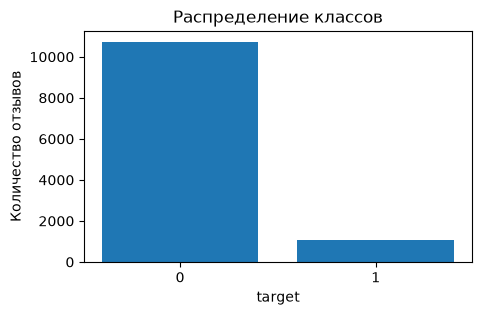

In [9]:
# Распределение классов: количество объектов каждого класса и их доля
target_distribution = (
    df["target"]
    .value_counts()
    .sort_index()
    .rename_axis("target")
    .reset_index(name="count")
)
target_distribution["share"] = target_distribution["count"] / len(df)

display(target_distribution)

plt.figure(figsize=(5, 3))
plt.bar(target_distribution["target"].astype(str), target_distribution["count"])
plt.title("Распределение классов")
plt.xlabel("target")
plt.ylabel("Количество отзывов")
plt.show()

Негативных отзывов на порядок меньше чем остальных. Мы имеем дело со значительным дисбалансом классов в решаемой задаче.

In [10]:
pd.set_option("display.max_colwidth", 220)

# Примеры объектов каждого класса: посмотрите, как выглядит текстовая разметка
for class_value, title in [(0, "ненегативные отзывы"), (1, "негативные отзывы")]:
    print(f"Примеры: {title}")
    examples = (
        df[df["target"] == class_value]
        [["text", "federal_district", "rubrics_count", "review_len_words", "emoji_count", "target"]]
        .sample(3, random_state=RANDOM_STATE)
    )
    display(examples)

Примеры: ненегативные отзывы


,text,federal_district,rubrics_count,review_len_words,emoji_count,target
1809,"Спасибо, Дмитрию за грамотный подбор экипировки для детей",Центральный ФО,3,8,0,0
3561,"Мне очень понравилось! Зашла туда случайно, хотелось выпить кофе с чем-нибудь вкусненьким.. Официантка очень приветливая и обходительная, предложила выбрать место, в зале очень уютно. Попробовала тосты с авокадо и Бо...",Центральный ФО,1,43,0,0
10301,"Всё просто супер! В номере есть всё необходимое, для автономного проживания. Особенно радует небольшая кухня с посудой, столовыми приборами, микроволновкой, электрочайником и плитой. А прямо под окнами есть супермарк...",Сибирский ФО,1,116,0,0


Примеры: негативные отзывы


,text,federal_district,rubrics_count,review_len_words,emoji_count,target
10728,"Совершенно отвратительное поведение дирекции: нужно было проехать по дороге (городская территория, как и весь МУП Рынок) - разгрузиться у соседнего здания. Как оказалось, въезд/проезд/пролёт на ранок стоит 800 рублей...",Центральный ФО,1,52,0,1
8118,"Купил велик ребёнку, он сломался через 3 недели эксплуатации, приехали в сервис, но тут его не приняли, записать могут через неделю не раньше, на просьбу уделить 2 минуты и оценить масштаб ремонта тоже отказали, хо...",Центральный ФО,2,88,0,1
11716,Ни в коем случае не посещайте данную мойку!\nПродолжают списывать деньги с карты после единоразового посещения!!!\nСписывают без моего ведома!,Центральный ФО,2,20,0,1


Сформулируйте выводы, кратко ответив на вопросы:

* Насколько классы сбалансированы?

* Почему accuracy здесь может вводить в заблуждение?

* Какие пропуски обнаружились и как с ними нужно поступить?

* Почему важно помнить, что `target` получен из пользовательских оценок, а не ручной разметкой текста?

- Классы, как отмечалось выше имеют дисбаланс - 1 (негативный отзыв) в 10 раз меньше чем остальных отзывов.
- Метрика Accuracy (доля правильных ответов) не может быть выбрана в качестве целевой метрики, так как будет вводить в заблуждение высоким показателем, обусловленным тем, что 90% отзывов имеют класс 0 (не негативные отзывы). Поэтому даже наивная модель всегда предсказывающая 0 будет иметь точность (accuracy) около 90%.
- В данных имеются 25 объектов с пропусками в столбце name_ru (название организации). Так как данный столбец не используется для обучения модели, нет необходимости устранять пропуски.
- Важно помнить, что target получен из пользовательских оценок, а не после ручной разметки текста, так как оценка не всегда коррелирует с текстом отзыва - иногда по ошибке пользователя, иногда преднамеренно.
  

In [11]:
# Напишите здесь решение для устранения пропусков, если обнаружили их

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Плюсик за то, что учитывается специфика target, сформированного по пользовательским оценкам, а не по ручной разметке тональности

## Шаг 3. Подготовка числовых признаков

Для первого эксперимента используйте готовые числовые признаки, закодированный признак `federal_district` и самостоятельно извлечённые из текста числовые показатели:

- `punct_count` — количество знаков препинания.
- `question_count` — количество вопросительных знаков.
- `exclamation_count` — количество восклицательных знаков.
- `newline_count` — количество переносов строк.
- `digit_count` — количество цифр.
- `uppercase_share` — доля заглавных букв среди всех букв.
- `avg_word_len` — средняя длина слова.

Выделив все признаки, разделите данные на обучающую, валидационную и тестовую выборки, а затем подготовьте данные для нейросети, создав объекты классов `Dataset` и `DataLoader`. Это же разделение нужно будет использовать и в эксперименте с текстовой моделью, чтобы сравнение было честным.

Не используйте признаки `name_ru`, `address` и `rubrics` в модели: они нужны для знакомства с данными, но могут привести к запоминанию конкретных организаций или слишком детальных категорий.

In [12]:
df_features = df.copy()
text = df_features["text"].astype(str)
punctuation = string.punctuation + "«»—–…“”„"

def count_char(line, chars):
    if chars == '\\n':
        return line.count('\\n')
    return len([c for c in list(line) if c in chars])

def count_by_condition(line, condition):
    return len([ch for ch in list(line) if condition(ch)])

# 1. Количество знаков препинания
df_features["punct_count"] = text.apply(lambda t: count_char(t, punctuation))
assert count_char('Прошлые -«а мы знали». \\nДавно была проверка! \\nПро', punctuation) == 7


# 2. Количество вопросительных знаков
df_features["question_count"] = text.apply(lambda t: count_char(t, '?'))
assert count_char('Прошлые -«а мы знали». \\nДавно была проверка! \\nПро???', '?') == 3


# 3. Количество восклицательных знаков
df_features["exclamation_count"] = text.apply(lambda t: count_char(t, '!'))
assert count_char('Прошлые -«а мы знали». \\nДавно была проверка! \\nПро', '!') == 1


# 4. Количество переносов строк
df_features["newline_count"] = text.apply(lambda t: count_char(t, '\\n'))
assert count_char('Прошлые -«а мы знали». \\nДавно была проверка! \\nПро', '\\n') == 2

# 5. Количество цифр
df_features["digit_count"] = text.apply(lambda t: count_char(t, string.digits))
assert count_char('Прошлые -«а мы знали111». \\nДавно была проверка01! \\nПро', string.digits) == 5

# 6. Доля заглавных букв среди всех букв
# Сначала посчитайте общее число букв и число заглавных букв
letters_count = text.apply(lambda t: count_by_condition(t, str.isalpha))
assert count_by_condition('abcAA 123', str.isalpha) == 5
upper_count = text.apply(lambda t: count_by_condition(t, str.isupper))
assert count_by_condition('abcAA 123', str.isupper) == 2
df_features["uppercase_share"] = upper_count/letters_count.replace(0, np.nan)
df_features["uppercase_share"] = df_features["uppercase_share"].fillna(0)

def avg_word_length(t):
    words = re.findall(r'\b\w+\b', t)
    return np.mean([len(x) for x in words])

assert avg_word_length('aaa bbbbb') == 4.0
assert avg_word_length('aaa, bbbbb!') == 4.0
# 7. Средняя длина слова
df_features["avg_word_len"] = text.apply(avg_word_length).replace(0, np.nan)
df_features["avg_word_len"] = df_features["avg_word_len"].fillna(0)
# display(df_features[["avg_word_len", 'text']].head(3))

numeric_features = [
    "rubrics_count",
    "emoji_count",
    "punct_count",
    "question_count",
    "exclamation_count",
    "newline_count",
    "digit_count",
    "uppercase_share",
    "avg_word_len",
    "review_len_chars",
    "review_len_words",
]

categorical_features = ["federal_district"]

display(df_features[numeric_features + ["target"]].describe().T)

district_distribution = (
    df_features["federal_district"]
    .value_counts()
    .rename_axis("federal_district")
    .reset_index(name="count")
)
district_distribution["share"] = district_distribution["count"] / len(df_features)
display(district_distribution)

,count,mean,std,min,25%,50%,75%,max
rubrics_count,11796.0,1.982791,1.095271,1.000000,1.000000,2.000000,3.000000,10.00
emoji_count,11796.0,0.320787,2.009054,0.000000,0.000000,0.000000,0.000000,173.00
punct_count,11796.0,12.085792,12.656860,0.000000,5.000000,8.000000,14.000000,186.00
question_count,11796.0,0.054256,0.393383,0.000000,0.000000,0.000000,0.000000,10.00
exclamation_count,11796.0,1.123093,2.346631,0.000000,0.000000,0.000000,1.000000,35.00
newline_count,11796.0,0.770515,2.177689,0.000000,0.000000,0.000000,0.000000,34.00
digit_count,11796.0,1.141573,3.270892,0.000000,0.000000,0.000000,1.000000,92.00
uppercase_share,11796.0,0.027950,0.016286,0.000000,0.017857,0.025362,0.034602,0.34
avg_word_len,11796.0,5.823385,0.771425,2.833333,5.285714,5.737705,6.266667,13.00
review_len_chars,11796.0,303.248813,290.872870,13.000000,145.000000,214.000000,362.000000,5460.00


,federal_district,count,share
0,Центральный ФО,4922,0.417260
1,Северо-Западный ФО,1922,0.162937
2,Южный ФО,1766,0.149712
3,Приволжский ФО,1547,0.131146
4,Сибирский ФО,589,0.049932
5,Уральский ФО,519,0.043998
6,Северо-Кавказский ФО,364,0.030858
7,Дальневосточный ФО,167,0.014157


Наблюдения по числовым признакам:
- есть выбросы в emoji_count (173 максимальное значение, 25 процентиль = 0)
- есть выбросы в punct_count (186 максимум, медиана - 8)
- есть выбросы в digit_count (92 максимум, 25 процентиль = 0)

Вывод: выбросы выглядят органическими. Не требуют обработки.

Наблюдения по категориальному столбцу с Федеральным округом:
- больше всего объектов в ЦФО (5к)
- другие большие ФО: СЗФО, ЮФО, ПФО

Наибольшее влияние будут оказывать объекты из ЦФО. В других более мелких регионах распределения могут отличаться в силу языковых отличий.

In [13]:
# Разделите данные на обучающую, валидационную и тестовую выборки в пропорции 70:15:15
# Не забудьте про стратификацию, чтобы сохранить долю негативных отзывов
train_df, temp_df = train_test_split(
    df_features,
    test_size=0.3,
    stratify=df_features['target'],
    random_state=RANDOM_STATE,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['target'],
    random_state=RANDOM_STATE,
)

split_stats = pd.DataFrame(
    {
        "rows": [len(train_df), len(val_df), len(test_df)],
        "target_share": [
            train_df["target"].mean(),
            val_df["target"].mean(),
            test_df["target"].mean(),
        ],
    },
    index=["обучающая", "валидационная", "тестовая"],
)

display(split_stats)

,rows,target_share
обучающая,8257,0.090953
валидационная,1769,0.091012
тестовая,1770,0.090960


In [14]:
# Создайте scaler для числовых признаков и encoder для federal_district
scaler = StandardScaler()
one_hot_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# Важно: fit только на обучающей выборке, для валидационной и тестовой используйте transform
X_train_num = scaler.fit_transform(train_df[numeric_features])
X_val_num = scaler.transform(val_df[numeric_features])
X_test_num = scaler.transform(test_df[numeric_features])

X_train_cat = one_hot_encoder.fit_transform(train_df[categorical_features])
X_val_cat = one_hot_encoder.transform(val_df[categorical_features])
X_test_cat = one_hot_encoder.transform(test_df[categorical_features])

X_train = np.hstack([X_train_num, X_train_cat]).astype("float32")
X_val = np.hstack([X_val_num, X_val_cat]).astype("float32")
X_test = np.hstack([X_test_num, X_test_cat]).astype("float32")

y_train = train_df["target"].values.astype("float32")
y_val = val_df["target"].values.astype("float32")
y_test = test_df["target"].values.astype("float32")

feature_names = numeric_features + list(
    one_hot_encoder.get_feature_names_out(categorical_features)
)

print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)
print("Количество признаков после кодирования:", len(feature_names))
display(pd.DataFrame({"feature": feature_names}))

X_train: (8257, 19) X_val: (1769, 19) X_test: (1770, 19)
Количество признаков после кодирования: 19


,feature
0,rubrics_count
1,emoji_count
2,punct_count
3,question_count
4,exclamation_count
5,newline_count
6,digit_count
7,uppercase_share
8,avg_word_len
9,review_len_chars


In [15]:
# Создание Dataset и DataLoader

class ReviewsDataset(Dataset):
    def __init__(self, features: np.ndarray, target: np.ndarray):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.target = torch.tensor(target, dtype=torch.float32)

    def __len__(self):
        # Верните количество объектов в датасете
        return len(self.target)

    def __getitem__(self, idx):
        # Верните пару: признаки объекта и целевую метку
        return self.features[idx], self.target[idx]


BATCH_SIZE = 128

numeric_loaders = {
    "train": DataLoader(
        ReviewsDataset(X_train, y_train),
        batch_size=BATCH_SIZE,
        shuffle=True,
    ),
    "val": DataLoader(
        ReviewsDataset(X_val, y_val),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
    "test": DataLoader(
        ReviewsDataset(X_test, y_test),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
}

features_batch, target_batch = next(iter(numeric_loaders["train"]))
print("features_batch:", features_batch.shape, features_batch.dtype)
print("target_batch:", target_batch.shape, target_batch.dtype)

features_batch: torch.Size([128, 19]) torch.float32
target_batch: torch.Size([128]) torch.float32


<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Разбиение на train, val и test выполнено в пропорции 70:15:15 со стратификацией

<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__

    
В numeric_features не вошли два готовых числовых признака - review_len_chars и review_len_words. По заданию они должны использоваться в первом эксперименте вместе с остальными числовыми признаками.Добавь их в список:
    
    
    numeric_features = [
        "rubrics_count",
        "review_len_chars",
        "review_len_words",
        "emoji_count",
        "punct_count",
        "question_count",
        "exclamation_count",
        "newline_count",
        "digit_count",
        "uppercase_share",
        "avg_word_len",
    ]

Сейчас после OHE получено 17 признаков, а после добавления двух недостающих должно получиться 19

<div class="alert alert-info"> ✅ <b>Комментарии студента:</b> Спасибо. Исправил и пересчитал. Вывод поправил.</div>

## Шаг 4. Эксперимент 1 — MLP на числовых признаках

Обучите несколько MLP-конфигураций. Во всех экспериментах используйте одно и то же разделение на выборки и одну и ту же функцию потерь.

Дополните код функций:

- `train_epoch` — нужна для одного прохода по обучающей выборке.
- `evaluate` — нужна для оценки на валидационной или тестовой выборках.

Функция `run_experiment` уже готова, её можно переиспользовать.

Из-за дисбаланса классов нужно добавить коэффициент `pos_weight` в `BCEWithLogitsLoss`. Это созданный для работы с нейросетями вариант модификации (взвешивания) функции потерь — знакомого вам метода борьбы с дисбалансом классов. Благодаря `pos_weight` ошибки на редком классе 1 получат больший вес. Это не отменяет необходимости выбирать конфигурации по PR-AUC и дополнительно анализировать ROC-AUC, precision, recall и F1.

In [16]:
def calc_metrics(y_true: np.ndarray, y_prob: np.ndarray, threshold: float = 0.5) -> dict:
    # PR-AUC и ROC-AUC считайте по вероятностям y_prob
    # Для precision, recall, F1 и accuracy сначала переведите вероятности в классы
    # В этом проекте используйте порог по умолчанию: threshold = 0.5
    y_pred = y_prob > threshold

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        zero_division=0,
    )

    return {
        "pr_auc": average_precision_score(y_true, y_prob),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy_score(y_true, y_pred),
    }


majority_accuracy = (test_df["target"] == 0).mean()
print(f"Accuracy константной модели, которая всегда предсказывает 0: {majority_accuracy:.3f}")

Accuracy константной модели, которая всегда предсказывает 0: 0.909


In [17]:
# Класс модели и обучение
class MLP(nn.Module):
    def __init__(self, input_dim: int, hidden_layers=(32, 16), dropout: float = 0.0):
        super().__init__()
        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        # Опишите прямой проход модели
        logits = self.net(x)
        return logits

In [18]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0

    for features, target in loader:
        features = features.to(device)
        target = target.to(device)

        # Выполните шаг обучения:
        # zero_grad → forward → loss → backward → step
        optimizer.zero_grad()
        logits = model(features)
        loss = criterion(logits, target.unsqueeze(1).float())
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(target)

    return total_loss / len(loader.dataset)


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_probs = []
    all_targets = []

    with torch.no_grad():
        for features, target in loader:
            features = features.to(device)
            target = target.to(device)

            # Выполните forward pass и посчитайте loss
            logits = model(features)
            loss = criterion(logits, target.unsqueeze(1).float())
            probs = torch.sigmoid(logits).squeeze(1)

            total_loss += loss.item() * len(target)
            all_probs.extend(probs.cpu().numpy())
            all_targets.extend(target.cpu().numpy())

    y_true = np.array(all_targets)
    y_prob = np.array(all_probs)
    metrics = calc_metrics(y_true, y_prob)
    metrics["loss"] = total_loss / len(loader.dataset)

    return metrics, y_true, y_prob

Вычисляем весовой коэффициент для учета дисбаланса классов и определяем метод эксперимента.

In [19]:
pos_weight_value = (y_train == 0).sum() / (y_train == 1).sum()
pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f"pos_weight: {pos_weight_value:.2f}")


def run_experiment(model, loaders: dict, config: dict):
    model = model.to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"],
    )

    history = []
    best_state = None
    best_val_pr_auc = -np.inf

    for epoch in range(1, config["epochs"] + 1):
        train_loss = train_epoch(model, loaders["train"], criterion, optimizer, device)
        val_metrics, _, _ = evaluate(model, loaders["val"], criterion, device)

        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                **val_metrics,
            }
        )

        if val_metrics["pr_auc"] > best_val_pr_auc:
            best_val_pr_auc = val_metrics["pr_auc"]
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
        print(
            f'\t{epoch}) train_loss={train_loss:0.2f}, val_loss={val_metrics["loss"]:0.2f}, val_pr_auc={val_metrics["pr_auc"]:0.6f}')

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

pos_weight: 9.99


In [20]:
mlp_configs = [
    {
        "name": "small_no_reg",
        "hidden_layers": (16,),
        "dropout": 0.0,
        "lr": 0.001,
        "weight_decay": 0.0,
        "epochs": 8,
    },
    {
        "name": "deep_no_reg",
        "hidden_layers": (64, 32),
        "dropout": 0.0,
        "lr": 0.001,
        "weight_decay": 0.0,
        "epochs": 8,
    },
    {
        "name": "regularized",
        "hidden_layers": (64, 32),
        "dropout": 0.3,
        "lr": 0.001,
        "weight_decay": 0.0001,
        "epochs": 8,
    },
]

In [21]:
mlp_histories = {}
mlp_models = {}
mlp_rows = []

for config in mlp_configs:
    print(f'Running config {config["name"]}')
    set_seed(RANDOM_STATE)

    model = MLP(
        input_dim=X_train.shape[1],
        hidden_layers=config["hidden_layers"],
        dropout=config["dropout"],
    )
    model, history = run_experiment(model, numeric_loaders, config)

    # Посчитайте метрики на test
    test_metrics, _, _ = evaluate(model, numeric_loaders['test'], criterion, device)

    mlp_rows.append(
        {
            "name": config["name"],
            "best_val_pr_auc": history["pr_auc"].max(),
            **test_metrics,
        }
    )
    mlp_histories[config["name"]] = history
    mlp_models[config["name"]] = model

mlp_results = (
    pd.DataFrame(mlp_rows)
    .sort_values("best_val_pr_auc", ascending=False)
    .reset_index(drop=True)
)

display(mlp_results.round(5))

Running config small_no_reg


	1) train_loss=1.23, val_loss=1.15, val_pr_auc=0.280304
	2) train_loss=1.12, val_loss=1.07, val_pr_auc=0.318041
	3) train_loss=1.05, val_loss=1.02, val_pr_auc=0.344197
	4) train_loss=1.01, val_loss=1.00, val_pr_auc=0.360752
	5) train_loss=0.98, val_loss=0.98, val_pr_auc=0.375952
	6) train_loss=0.96, val_loss=0.97, val_pr_auc=0.382270
	7) train_loss=0.96, val_loss=0.97, val_pr_auc=0.390683
	8) train_loss=0.95, val_loss=0.96, val_pr_auc=0.395816
Running config deep_no_reg
	1) train_loss=1.13, val_loss=1.01, val_pr_auc=0.345805
	2) train_loss=0.98, val_loss=0.96, val_pr_auc=0.394610
	3) train_loss=0.95, val_loss=0.96, val_pr_auc=0.402952
	4) train_loss=0.94, val_loss=0.96, val_pr_auc=0.413257
	5) train_loss=0.93, val_loss=0.95, val_pr_auc=0.415361
	6) train_loss=0.92, val_loss=0.95, val_pr_auc=0.418593
	7) train_loss=0.91, val_loss=0.94, val_pr_auc=0.415496
	8) train_loss=0.91, val_loss=0.95, val_pr_auc=0.416889
Running config regularized
	1) train_loss=1.17, val_loss=1.04, val_pr_auc=0.3

,name,best_val_pr_auc,pr_auc,roc_auc,precision,recall,f1,accuracy,loss
0,regularized,0.42202,0.39424,0.82166,0.25482,0.73913,0.37898,0.77966,0.94328
1,deep_no_reg,0.41859,0.39485,0.82199,0.26067,0.72050,0.38284,0.78870,0.94176
2,small_no_reg,0.39582,0.38989,0.81918,0.24694,0.75155,0.37174,0.76893,0.95553


**Дополнительное задание**

Четвёртую конфигурацию `extra` можно делать после того, как у вас запускаются три базовые конфигурации и появляется таблица результатов. Сдать проект можно и без неё.

Если выполняете допзадание, заполните блок `extra_config` в следующей ячейке. Перед запуском кратко обоснуйте параметры: размер слоёв, `dropout`, `lr` и `weight_decay`.

In [22]:
# # Дополнительное задание
# # Когда три базовые конфигурации работают, заполните блок ниже
# extra_config = {
#   "name": "extra",
#   "hidden_layers": ...,  # например, (32, 16)
#   "dropout": ...,
#   "lr": ...,
#   "weight_decay": ...,
#   "epochs": 8,
# }

# model = MLP(
#   input_dim=X_train.shape[1],
#   hidden_layers=extra_config["hidden_layers"],
#   dropout=extra_config["dropout"],
# )
# model, history = run_experiment(model, numeric_loaders, extra_config)

# # Посчитайте метрики на test
# test_metrics, _, _ = evaluate(..., ..., ..., ...)

# # Добавляем результаты в mlp_rows и пересобираем отчёт
# mlp_rows.append(
#         {
#             "name": extra_config["name"],
#             "best_val_pr_auc": history["pr_auc"].max(),
#             **test_metrics,
#         }
#     )

# mlp_histories[extra_config["name"]] = history
# mlp_models[extra_config["name"]] = model

# mlp_results = (
#     pd.DataFrame(mlp_rows)
#     .sort_values("best_val_pr_auc", ascending=False)
#     .reset_index(drop=True)
# )

# display(mlp_results.round(4))


Если вы выполняли дополнительную конфигурацию `extra`, сопоставьте ожидания с результатом:

* стала ли модель стабильнее;
* улучшился ли PR-AUC;
* как изменились ROC-AUC, precision и recall;
* есть ли признаки переобучения согласно данным кривых loss.

In [23]:
best_mlp_name = mlp_results.iloc[0]["name"]
best_mlp_model = mlp_models[best_mlp_name]

best_mlp_path = MODELS_DIR / "best_mlp_numeric.pt"

# Сохраните веса лучшей MLP через state_dict
torch.save(best_mlp_model.state_dict(), best_mlp_path)

print(f"Лучшая MLP-конфигурация по PR-AUC на валидационной выборке: {best_mlp_name}")
print(f"state_dict сохранён в: {best_mlp_path}")

Лучшая MLP-конфигурация по PR-AUC на валидационной выборке: regularized
state_dict сохранён в: models/best_mlp_numeric.pt


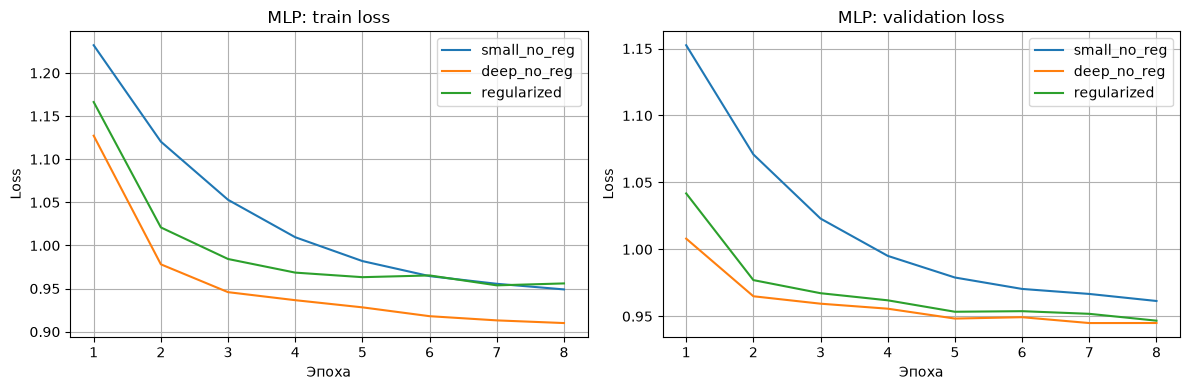

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, history in mlp_histories.items():
    # Постройте train loss и validation loss для каждой конфигурации
    axes[0].plot(history['epoch'], history['train_loss'], label=name)
    axes[1].plot(history['epoch'], history['loss'], label=name)

axes[0].set_title("MLP: train loss")
axes[1].set_title("MLP: validation loss")

for ax in axes:
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Loss")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

**Вывод по эксперименту 1**

Соберите результаты в одну сравнительную таблицу. Постройте кривые обучения и сравните поведение моделей. Ответьте на вопросы:

* Какая MLP-конфигурация сработала лучше с точки зрения метрики PR-AUC? Что показывают остальные метрики этого запуска?
* Продолжает ли уменьшаться loss на обучающей выборке, когда loss на валидационной выборке уже растёт или перестаёт улучшаться?
* Помогли ли слои `Dropout` и `weight_decay` уменьшить переобучение?
* Почему числовых признаков может быть недостаточно для анализа тональности?

Если вы выполняли дополнительное задание, также расскажите, совпали ли ожидания от конфигурации с результатом.

- Про лучший PR-AUC на val:
    - По PR-AUC на val выиграл regularized - двухслойная сеть 64-32, с регуляризацией dropout и weight_decay (максимум 0.422).
    - deep_no_reg - та же глубина на val 0.419, разница с regularized незначительна.
    - small_no_reg - один скрытый слой на 16 нейронов, без регуляризации, отстаёт (0.396): слишком простая модель.
    
- Про лосс на графиках:
    - На графиках loss train у всех идёт вниз все 8 эпох.
    - Val loss у deep и regularized после 2-3 эпохи в основном стоит около 0.95-0.96, а PR-AUC на val ещё улучшается - полезно смотреть на оба графика, потому что слепой early stop мог остановить процесс ранььше оптимального.
- Про переобучение:
    - Dropout и weight_decay, используемые в регуляризации, не позволили "выучить" тренировочные данные - зеленый график на трейн лосс выходит на плато, а нерегуляризованный вариант модели продолжает падать. Но на валидации разница несущественна.
- Вывод:
    - Числовых фич (длина, пунктуация, счётчики) для тональности маловато: модель цепляется за косвенные признаки, а не за формулировки. Отсюда скромный PR-AUC.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

train_epoch и evaluate реализованы корректно. В текущем запуске лучшей оказалась deep_no_reg с validation PR-AUC 0.41693

<div class="alert alert-info"> ✅ <b>Комментарии студента:</b> Актуализировал вывод: лучшая модель - regularized с PR-AUC 0.422.</div>


## Шаг 5. Эксперимент 2 — Embedding + mean pooling + MLP

В ходе второго эксперимента вы передадите в нейросеть тексты отзывов, а не только их числовые признаки. Используйте те же обучающую, валидационную и тестовую выборки, что и в первом эксперименте.

Далее вам нужно:

1. Подготовить текст — использовать готовую токенизацию, построить словарь только по обучающей выборке и перевести слова в индексы.
2. Собрать `Dataset` для текстов — реализовать длину датасета, получение одного объекта, обрезание длинных отзывов и пэддинг коротких отзывов до `MAX_LENGTH`.
3. Описать модель — получить эмбеддинги, исключить PAD-токены маской, усреднить эмбеддинги настоящих токенов и передать итоговый вектор в MLP.
4. Обучить модель через уже готовый `run_experiment`, оценить качество на тестовой выборке и сохранить веса через `state_dict`. Новый цикл обучения писать не нужно.
5. Провести анализ ошибок: найти конкретные примеры ответов типа FP и FN, чтобы объяснить, почему модель могла ошибиться.

### 5.1. Готовая подготовка текста

Код для токенизации и построения словаря уже почти полностью готов. Ваша задача — запустить ячейку и проверить, что словарь действительно строится **только по обучающей выборке**.

Обратите внимание на три специальных элемента логики:

- `PAD_IDX` — индекс для добивки коротких текстов до одной длины.
- `UNK_IDX` — индекс для редких или неизвестных слов. Подробнее этот элемент вы рассмотрите в следующем спринте.
- `text_to_indices` — функция, которая превращает текст в список индексов словаря.

После запуска проверьте размер словаря и первые элементы: это быстрый способ убедиться, что подготовка текста прошла корректно.

In [25]:
TOKEN_RE = re.compile(r"[а-яёa-z0-9]+", flags=re.IGNORECASE)
PAD_IDX = 0
UNK_IDX = 1


def tokenize(text: str) -> list[str]:
    return TOKEN_RE.findall(str(text).lower())


def build_vocab(texts, min_freq: int = 2, max_size: int = 20_000) -> dict:
    counter = Counter()
    for text in texts:
        counter.update(tokenize(text))

    vocab = {"<PAD>": PAD_IDX, "<UNK>": UNK_IDX}
    for token, count in counter.most_common(max_size - len(vocab)):
        if count >= min_freq:
            vocab[token] = len(vocab)

    return vocab


def text_to_indices(text: str, vocab: dict) -> list[int]:
    return [vocab.get(token, UNK_IDX) for token in tokenize(text)]


vocab = build_vocab(train_df["text"], min_freq=2, max_size=20_000)
print(f"Размер словаря: {len(vocab)}")
print("Первые элементы словаря:", list(vocab.items())[:10])

Размер словаря: 18985
Первые элементы словаря: [('<PAD>', 0), ('<UNK>', 1), ('и', 2), ('в', 3), ('на', 4), ('не', 5), ('очень', 6), ('с', 7), ('что', 8), ('все', 9)]


### 5.2. Dataset и пэддинг

В этой части нужно дописать класс `ReviewsTextDataset`:

1. Верните количество текстов в датасете в `__len__`.
2. Возьмите текст по индексу и переведите его в индексы токенов в `__getitem__`.
3. Обрежьте слишком длинные отзывы до `MAX_LENGTH`.
4. Дополните короткие отзывы значением `PAD_IDX`, чтобы все последовательности в батче были одинаковой длины.
5. Создайте `DataLoader` для обучающей, валидационной и тестовой выборок.
6. Проверьте форму первого батча: ожидается матрица размера `batch_size` × `MAX_LENGTH` и тип `torch.long` для индексов токенов.

In [26]:
class ReviewsTextDataset(Dataset):
    def __init__(self, texts, target, vocab: dict, max_length: int = 120):
        self.texts = list(texts)
        self.target = np.array(target, dtype=np.float32)
        self.vocab = vocab
        self.max_length = max_length

    def __len__(self):
        # Верните количество текстов
        return len(self.texts)

    def __getitem__(self, idx):
        ids = text_to_indices(self.texts[idx], self.vocab)

        # Обрежьте последовательность до max_length
        ids = ids[:self.max_length]

        # Если последовательность короче max_length, добавьте PAD_IDX
        if len(ids) < self.max_length:
            ids = ids + [PAD_IDX] * (self.max_length - len(ids))

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(self.target[idx], dtype=torch.float32),
        )


MAX_LENGTH = 120

text_loaders = {
    "train": DataLoader(
        ReviewsTextDataset(train_df["text"], y_train, vocab, max_length=MAX_LENGTH),
        batch_size=BATCH_SIZE,
        shuffle=True,
    ),
    "val": DataLoader(
        ReviewsTextDataset(val_df["text"], y_val, vocab, max_length=MAX_LENGTH),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
    "test": DataLoader(
        ReviewsTextDataset(test_df["text"], y_test, vocab, max_length=MAX_LENGTH),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
}

ids_batch, text_target_batch = next(iter(text_loaders["train"]))
print("ids_batch:", ids_batch.shape, ids_batch.dtype)
print("target_batch:", text_target_batch.shape, text_target_batch.dtype)

ids_batch: torch.Size([128, 120]) torch.int64
target_batch: torch.Size([128]) torch.float32


<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

ReviewsTextDataset дополнен правильно. Тексты переводятся в индексы токенов, обрезаются до MAX_LENGTH, короткие последовательности дополняются PAD_IDX

### 5.3. Модель с Embedding и mean pooling

В этой части нужно дописать `forward` модели `EmbeddingMLP`.

Что вам нужно сделать внутри `forward`:

1. Передать `input_ids` в `nn.Embedding`, чтобы каждому индексу токена соответствовал обучаемый вектор.
2. Умножить эмбеддинги на маску и посчитать длину каждого текста без PAD-токенов.
3. Выполнить mean pooling: усреднить эмбеддинги настоящих токенов и получить один вектор на отзыв.
4. Передать этот вектор в MLP-классификатор и вернуть логит.

In [27]:
class EmbeddingMLP(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        embedding_dim: int = 64,
        hidden_dim: int = 64,
        dropout: float = 0.3,
        pad_idx: int = PAD_IDX,
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx,
        )
        self.classifier = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )
        self.pad_idx = pad_idx

    def forward(self, input_ids):
        # 1. Получите эмбеддинги
        # [B, L] -> [B, L, E]
        embeddings = self.embedding(input_ids)

        # 2. PAD-токены нужны только для выравнивания длин
        # Маска помогает не учитывать их при усреднении
        mask = (input_ids != self.pad_idx).unsqueeze(-1)
        masked_embeddings = embeddings * mask
        lengths = mask.sum(dim=1).clamp(min=1)

        # 3. Выполните mean pooling и передайте результат в MLP
        pooled = (embeddings * mask).sum(dim=1) / lengths
        logits = self.classifier(pooled)
        return logits

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

Mean pooling реализован корректно

### 5.4. Обучение, оценка и сохранение

Используйте тот же `run_experiment`, что и для MLP на числовых признаках. Это важно: цикл обучения и цикл валидации не нужно писать второй раз.

Что нужно сделать в коде:

1. Проверьте конфигурацию текстовой модели: размер эмбеддинга, размер скрытого слоя, `dropout`, `lr` (learning rate), `weight_decay` и число эпох.
2. Создайте объект `EmbeddingMLP` с нужным размером словаря.
3. Запустите обучение через `run_experiment`.
4. Посчитайте метрики на тестовой выборке с помощью `evaluate`.
5. Постройте график loss на обучающей и валидационной выборках.
6. Сохраните веса обученной текстовой модели через `state_dict`.

In [28]:
text_config = {
    "embedding_dim": 64,
    "hidden_dim": 64,
    "dropout": 0.3,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "epochs": 8,
}

set_seed(RANDOM_STATE)

text_model = EmbeddingMLP(
    vocab_size=len(vocab),
    embedding_dim=text_config["embedding_dim"],
    hidden_dim=text_config["hidden_dim"],
    dropout=text_config["dropout"],
)

text_model, text_history = run_experiment(text_model, text_loaders, text_config)
text_test_metrics, y_true_text_test, y_prob_text_test = evaluate(
    text_model,
    text_loaders["test"],
    criterion,
    device,
)

display(pd.DataFrame([text_test_metrics]).round(4))

	1) train_loss=1.22, val_loss=1.15, val_pr_auc=0.315074
	2) train_loss=1.00, val_loss=0.84, val_pr_auc=0.442851
	3) train_loss=0.67, val_loss=0.70, val_pr_auc=0.547129
	4) train_loss=0.52, val_loss=0.65, val_pr_auc=0.606270
	5) train_loss=0.41, val_loss=0.64, val_pr_auc=0.629195
	6) train_loss=0.34, val_loss=0.64, val_pr_auc=0.644275
	7) train_loss=0.28, val_loss=0.65, val_pr_auc=0.661587
	8) train_loss=0.24, val_loss=0.67, val_pr_auc=0.669070


,pr_auc,roc_auc,precision,recall,f1,accuracy,loss
0,0.6304,0.9408,0.4746,0.8137,0.5995,0.9011,0.6619


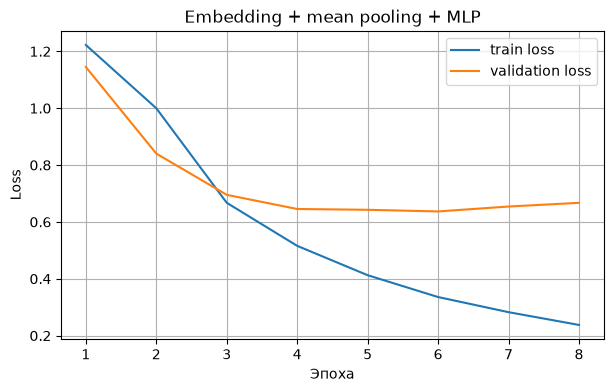

In [29]:
plt.figure(figsize=(7, 4))

# Постройте train loss и validation loss для текстовой модели
plt.plot(range(1, len(text_history)+1), text_history["train_loss"], label="train loss")
plt.plot(range(1, len(text_history)+1), text_history["loss"], label="validation loss")

plt.title("Embedding + mean pooling + MLP")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()

In [30]:
best_text_path = MODELS_DIR / "best_embedding_mlp.pt"

# Сохраните веса текстовой модели через state_dict
torch.save(text_model.state_dict(), best_text_path)

print(f"state_dict текстовой модели сохранён в: {best_text_path}")

state_dict текстовой модели сохранён в: models/best_embedding_mlp.pt


### 5.5. Анализ ошибок текстовой модели

После обучения нужно посмотреть на конкретные ошибки, чтобы разобраться, что именно не ухватывает модель.

Что нужно найти:

- Ложноположительные примеры (FP) — модель посчитала отзыв негативным (класс 1), хотя его истинный класс равен 0.
- Ложноотрицательные примеры (FN) — модель не распознала негативный отзыв (класс 1).

Для каждого типа ошибки проанализируйте текст, вероятность негативного отзыва и возможную причину. Обратите внимание на смешанную тональность, короткие отзывы, отрицания, сарказм, длинный контекст и потерю порядка слов при mean pooling.

Также учитывайте возможный шум разметки: `target` получен из пользовательской оценки, а не из ручного анализа текста.

In [31]:
error_analysis = test_df[["text", "target", "review_len_words"]].copy()
error_analysis["prob_negative"] = y_prob_text_test
error_analysis["prediction"] = (error_analysis["prob_negative"] >= 0.5).astype(int)

# Найдите false positive: модель считает отзыв негативным, но target = 0
# Полезно отсортировать такие примеры по prob_negative по убыванию
fp_mask = (error_analysis["prediction"] == 1) & (error_analysis["target"] == 0)
false_positive = error_analysis[fp_mask].sort_values(by="prob_negative", ascending=False)

# Найдите false negative: модель пропускает негативный отзыв
# Полезно отсортировать такие примеры по prob_negative по возрастанию
fn_mask = (error_analysis["prediction"] == 0) & (error_analysis["target"] == 1)
false_negative = error_analysis[fn_mask].sort_values(by="prob_negative", ascending=True)

pd.set_option('display.max_colwidth', 1000) # выводить больше символов в ячейке
print("False positive: модель считает отзыв негативным, но target = 0")
display(false_positive.head(15))

print("False negative: модель пропускает негативный отзыв")
display(false_negative.head(15))

False positive: модель считает отзыв негативным, но target = 0


,text,target,review_len_words,prob_negative,prediction
3917,Обычная поликлиника. Со вмеми плюсами и минусами,0,7,0.998248,1
8876,"Консультантов в зале нет ,выбор не большой",0,7,0.998181,1
10024,"Контора с понятиями! Встречают как надо,обещания выполняют. Справки не нужны,можно даже ВИЧ инфицированным работать. Главное при отлове птиц не повредить кожный покров. Чтоб не попасть в просак",0,29,0.994509,1
7011,"Оказались закрыты, без всяких объявлений, даже на сайте не видно было, зря потратил время и деньги за доставку груза к филиалу. Целых три звезды за то, что сам сглупил и заранее не позвонил.",0,33,0.993829,1
4011,"Медленно, печально,на кассе такое ощущение что просто тянут время.\nОдин сотрудник в отделе декора,которому просто не разорваться",0,19,0.992189,1
5206,"Водитель на отгрузке простоял в очереди за фурами 2 часа, что бы загрузить 800 кг. Сотрудники аргументировали тем, что у меня металл с порезкой, а так бы без очереди отгрузили... В итоге уехали без груза, т к. уже на объекте не кому разгружать было. Приехали грузиться на следующий день. Короче можно быстро отгрузиться, если повезёт и не будет очереди. Но я попал на 2 часа газели, и + на 3 часа на следующий день опять газель. В другом месте было бы на 1 % дороже, но в итоге дешевле.",0,87,0.989035,1
1304,"Очень долго не публикуют на какой путь и платформу приходит поезд. Проход к разным платформам в разные стороны. Люди вынуждены толпиться в центральном зале перед табло, а потом бегом бежать к поезду и искать вагон в котором приехали гости.... Неужели диспетчерская служба не знает на какой путь какой поезд будут ставить????",0,51,0.987329,1
996,"Неудачное знакомство с клубом. Отдыхали на базе отдыха рядом,хотели покататься на лошадях. Заранее звонила администратору. Чтобы записать взрослых и детей,сначала надо звонить тренеру по времени для взрослых,потом опять звонить администратору про детей. Неудобно. Ответ тренера ждала сутки в вотсап. Детей не записали,сказали,будут свободны - прокатит. (Хотя расписано что есть занятия для любого возраста на пони). Ок. Договаривались на 16. Приехали в 16-03. Звоним что подъехали - в ответ сразу претензии - вы опаздали и ещё должны были звонить заранее,а не когда зашли. Тренер подошла,опять начала говорить что опаздали,лошади не готовы. А почему они не готовы,если нас записали? Я же не отменяла занятие! Если вы так беспокоитесь,что мы не приедем - звоните сами уточняйте. От такой встречи мы отказались заниматься. Детей прокатили - 1 круг (300р) это секунд 20. На большой лошади , пони нет.\n\nЯ так поняла,новых посетителей здесь не ценят. Про задержку (3 минуты!) Можно было сказать по-д...",0,184,0.984220,1
3912,"Убрала 2 звезды за время ожидания. Обещают 8-9 минут, по факту крайний раз ждала 21, это при отсутствии заказов передо мной.\nПовар на расслабоне готовит, особо не торопясь.",0,29,0.981328,1
10755,"Отличное заведение. \n\nОчень красивый, стильный с силами деталями интерьер. \nХочет чудесный. \n\nПосадили на веранде. Принесли тепловую пушку. Интересовались, как мне еда. \n\nЗаказала салат из хурмы с козьим сыром, хинкали с ягнёнком и чай. \n\nСалат был абсолютно не вкусный огромные куски хурмы. 4 шапочки козьего(?) сыра, который вообще я не опознала. на вкус безликий творожный сыр. \nОчень мало заправки. \nна мой взгляд полный дисбаланс вкуса. \n\nПоковыряла, отставили. Девушка хост сразу увидела, примчалась. Пригласила администратора. Салат отнесли повару. Который сказал, что так и должно быть. Если жит так, то не берите этот салат. Это просто деньги на ветер. Ну и салат из чека не убрали. \n\nВ итоге, мне в качестве комплемента принесли десерт а-ля Павлова. Вот десерт был великооепен. Потрясающий, нежный, не приторный. Огонь. \n\nХинкали тоже на высоте. Тесто тонкое, бульончик внутри. Начинка сочная. \n\n Тем не менее, совете жто заведение от души. \nА салат рекомендую до...",0,155,0.977306,1


False negative: модель пропускает негативный отзыв


,text,target,review_len_words,prob_negative,prediction
9989,"Цены зашкаливают, не для нашего города.",1,6,0.000055,0
8255,"И место хорошее и обслуживание замечательно и вежливы и приветливы и аккуратны , Одно очень расстроило Мороженное Отвратительное ледышки вместо замечательного лакомства",1,21,0.001220,0
5658,"Не нравиться, особенно если ехать с города! Если есть варианты и альтернативы , туда не поеду 😩",1,15,0.005997,0
1903,Очень долго ходить автобус,1,4,0.012574,0
277,"Проблема попасть к терапевту и эндокринологу, проблема выстоять в очереди для сдачи крови на анализы, особенно для пожилых людей, за то за деньги без очереди . вывод положенное по омс лечение практически не доступно, так как к врачам попасть невозможно",1,39,0.020882,0
11718,Очень бедная больница. Все лекарства для лечения покупали сами .. Также была аллергия у ребёнка ни кто не дал даже таблетки от аллергии. Сказали нету... Дети и взрослые лежат все вместе. Одно радовала то что женщины и мужчины в разных палатах.Лежала дочка в лор отделение.,1,45,0.032663,0
7559,"Первый раз в жизни решила обратиться к специалистам, так как у меня была роспись. Хотелось быть красивой. У девочек очень хороший клиентский сервис, они оч внимательные, подождали меня, собрали. Но собрали просто ужасно, через час моя причёска и макияж превратились в гавно, я стала похожа на старуху, макияж подчеркнул даже те морщины, которых нет. Это просто одно огромное разочарование. Испортили мне такой праздник. \n",1,64,0.062797,0
10010,"Раньше была классная шаверма, но со временем начали портиться. Начали экономить на соусе, в шаверму кладут буквально чайную ложку. Из за этого шаверма становится сухой. Очень хочу чтобы исправились",1,29,0.067484,0
5214,Компания полное днище. Скорость восстановления соединения с интернетом на нуле. Цены высокие. Рассмотрение обращений долгое. На своих клиентов наплевать. Пользуются своей монополией. Не советую. Если есть альтернативный вариант лучше рассмотрите его. Обслуживание плохое. Персонал вежлив ео при этом время ожидания решения проблемы долгое. Расположение шикарное.,1,45,0.078442,0
9761,"Самый худший Бургер Кинг в городе, работники просто позорят всю империю Бургер Кинг, Кинг авто долго работает, обычно со своими у окошко стоят и общаются.\n",1,26,0.117075,0


**Анализ найденных ошибок**

Заполните два коротких списка:

- FP — какие слова или фрагменты могли подтолкнуть модель посчитать отзыв отрицательным, хотя `target = 0`.
- FN — почему модель могла пропустить отзыв класса 1. Возможные причины: редкие слова, длинный контекст, отрицания или слабые негативные маркеры.

Отдельно отметьте, могли ли дисбаланс классов и разметка по пользовательским оценкам повлиять на ошибки: отзывы с оценкой 3–5 попадают в `target = 0`, хотя текст иногда бывает нейтральным или смешанным.

Рассматриваем топ FP/FN по prob_negative: для FP - самые уверенные ложные срабатывания, для FN - где модель почти уверена, что отзыв не негативный.

False positive:
- Проблема: текст явно негативный, но таргет размечен как 0 (то есть отзыв нейтральный или положительный согласно оценке по количеству звезд).
    - Примеры: длинная история про конный клуб (prob ~0.98), очередь на вокзале (~0.99), "убрала 2 звезды за ожидание" (~0.98), "зря потратил время" при трёх звёздах (~0.99). Модель цепляется за "неудобно", "опоздали", "долго", "не публикуют" - по словам это минус.
    - Вывод: ошибка в таргете, а не в модели.
- Проблема: смешанная тональность.
    - Примеры: ресторан - в начале "отличное заведение", дальше разбор салата и претензии, в конце снова рекомендация (prob ~0.98).
    - Вывод: модель не может различить "отличное заведение" и "отличный салат", mean pooling усредняет эмбеддинг отзыва, повышая вероятность негативного тона, тогда как оценка пользователя в целом положительная.
- Проблема: короткие отзывы.
    - Примеры: "Со всеми плюсами и минусами" (~0.99), "выбор не большой" (~0.99) - по 7 слов.
    - Вывод: мало контекста, зато есть "минусами", "нет", "не большой".
- Проблема: много отрицаний в положительном отзыве
    - Пример: "Здравствуйте! Восторг!" (0.97), но далее много отрицаний "не осветляется" и т.п.
    - Вывод: без учета порядка слов негативные частицы могут тянуть эмбеддинг в негативную сторону.

False negative:
- Проблема: короткие отзывы.
    - Примеры: "Цены зашкаливают, не для нашего города" - prob ~0.00005; "Очень долго ходить автобус" - prob ~0.01.
    - Вывод: мало токенов после усреднения, сигнал слишком слабый.
- Проблема: противоречивые отзывы.
    - Пример: "И место хорошее и обслуживание замечательно...", в конце "мороженое отвратительное", "помещение в ужасном состоянии", но "врачи в основном хорошие".
    - Вывод: позитивные эмбеддинги при пулинге передавливают негативные. В целом это спорные отзывы, пограничные. Ручная разметка могла бы помочь, но она тоже в данном случае может быть субъективна.
- Проблема: сарказм не улавливается
    - Пример: "Тесто огонь, начинки почти нет".
    - Вывод: при "положительных" словах в тексте, модель не улавливает саркастический нагативный тон.
- Пробшема: реальные ошибки модели
    - Примеры: "Самый худший Бургер Кинг", "Компания полное днище", "Самые мерзкие креветки".
    - Вывод: вероятно, модель перестраховывается из-за редкого класса 1 в указанных примерах.

Отдельно отметим:
- дисбаланс классов может влиять на ошибки модели FN, модель "перестраховывается" из-за редкого класса 1.
- разметка по пользовательским оценкам может быть шумна, как мы видели на примерах, что влияет на ошибки FP и FN.

**Вывод по эксперименту 2**

Ответьте на вопросы:

* Насколько текстовая модель лучше или хуже MLP на числовых признаках по PR-AUC? Что показывают остальные метрики?
    - по метрикам текстовая модель на эмбеддингах оказалась лучше MLP на числовых признаках: PR-AUC 0.63 против 0.39. По F1 (0.60 vs 0.38), precision (0.47 vs 0.26) и recall (0.81 vs 0.74) картина та же.
* Какие ошибки вы нашли среди false positive и false negative?
    - FP: ошибки часто связаны с неверной разметкой таргета - пользователи ставят 3+ звезд, но текст отзыва негативный на самом деле. Также из-за токенизации пословно положительные отзывы, содержащие негативные слова "не", например, "не осветляется" улавливаются моделью как негатив. Часто модель ошибается на длинных отзывах, где перемешаны как позитивные так и негативные части: в целом заведение может быть оценено положительно, но описанные недостатки в тексте тянут эмбеддинг в негативную сторону.
    - FN: Саркастические отзывы модель считает за положительные. Так же есть проблемы на коротких отзывах без явного негатива, модель перестраховывается, как и на некоторых явно негативных рецензиях.
* Какие причины ошибок кажутся наиболее вероятными?
    - Шум разметки таргета: звезды оценки не всегда коррелируют с текстом отзыва.
    - Mean Pooling игнорирует порядок слов, особенно в FP вердиктах, когда "не" встречается в потизивном контексте ("не плохо", "не дорого" и тп).
    - Дисбаланс классов: модель перестраховывается из-за редкого класса 1.
* Какие ограничения остаются у mean pooling?
    - Так как эмбеддинги всех слов усредняются и строится один вектор для всего отзыва, и все слова имеют одинаковый вес, то смешанные тексты, "не с глаголом", сарказм и длинный текст, обрезанный по максимальному числу токенов, снижают качество финального вектора и эффективность модели. 
* Почему текстовое представление обычно даёт модели больше информации, чем поверхностные числовые признаки?
    - Числа описывают только форму отзыва, но не сами формулировки и семантику слов. Эмбеддинги слов напротив, дают связь со смыслом и обучаются в контексте всего текста и учитывают таргет.

<div class="alert alert-block alert-success">✔️
    

__Комментарий от ревьюера №1__

FP и FN найдены правильно. Анализ выполнен на конкретных отзывах с вероятностями модели

## Шаг 6. Итоговое сравнение

Для честного выбора лучшей числовой MLP используйте PR-AUC на валидационной выборке, потому что положительный класс редкий. ROC-AUC, precision, recall, F1 и accuracy нужны для дополнительной диагностики. Метрики на тестовой выборке анализируем уже после выбора модели.

Ниже соберите сравнительную таблицу минимум с двумя строками: лучшая MLP на числовых признаках и `Embedding + pooling + MLP`.

In [32]:
best = mlp_results.iloc[0]

final_comparison = pd.DataFrame(
    [
        {
            'Подход': 'MLP на числовых признаках',
            'PR-AUC test': best['pr_auc'],
            'ROC-AUC test': best['roc_auc'],
            'Precision': best['precision'],
            'Recall': best['recall'],
            'F1': best['f1'],
            'Ограничения': 'Только числовые признаки, без текста и порядка слов',
        },
        {
            'Подход': 'Embedding + pooling + MLP',
            'PR-AUC test': text_test_metrics['pr_auc'],
            'ROC-AUC test': text_test_metrics['roc_auc'],
            'Precision': text_test_metrics['precision'],
            'Recall': text_test_metrics['recall'],
            'F1': text_test_metrics['f1'],
            'Ограничения': 'Mean pooling, обрезка длины, нет порядка слов.',
        },
    ]
)

display(final_comparison)

,Подход,PR-AUC test,ROC-AUC test,Precision,Recall,F1,Ограничения
0,MLP на числовых признаках,0.394239,0.821655,0.254818,0.739130,0.378981,"Только числовые признаки, без текста и порядка слов"
1,Embedding + pooling + MLP,0.630350,0.940810,0.474638,0.813665,0.599542,"Mean pooling, обрезка длины, нет порядка слов."


<div class="alert alert-block alert-danger">✍
    

__Комментарий от ревьюера №1__

После исправления numeric_features таблицу потребуется пересчитать, поскольку числовой эксперимент изменится

<div class="alert alert-info"> ✅ <b>Комментарии студента:</b> Пересчитана таблица.</div>


## Итоговые выводы

Сформулируйте итоговые выводы. Ответьте на вопросы:

* Какой подход показал лучшее качество?
    - Лучше embedding + mean pooling + MLP. На тесте она обходит лучшую числовую MLP (regularized) по всем основным метрикам; ключевая метрика при редком классе - PR-AUC.
* По каким метрикам преимущество особенно заметно?
    - Сильнее всего разрыв по PR-AUC (около 0.63 против 0.39) и F1 (около 0.60 против 0.38). Precision и recall у текстовой модели тоже выше. ROC-AUC у нее выше, но для дисбаланса важнее смотреть на PR-AUC.
* Что текстовая модель узнала из того, что упускала модель на числовых признаках?
    - Числовая MLP видит длину, пунктуацию, регион - не сами формулировки. Текстовая цепляет лексику жалоб и похвалы ("худший", "очередь", "отвратительно", "не советую") и их сочетания в отзыве. Это и даёт прирост качества.
* В каких ситуациях числовые признаки всё же могут быть полезны?
    - Когда нужен быстрый и дешевый скоринг без словаря и эмбеддингов, в качестве бейзлайна.
* Какие ограничения есть у mean pooling?
    - Один вектор на весь отзыв, все слова с одинаковым весом: страдают смешанная тональность, отрицания, сарказм, длинные тексты и обрезка по MAX_LENGTH. Порядок слов не учитывается.
* Как на результат могли повлиять дисбаланс классов и разметка, полученная из пользовательских оценок?
    - Около 9% объектов имеют класс 1. Метрику Accurracy при этом оценивать нет большого резона, даже наиваня модель будет иметь высокий скор. В нашем случае pos_weight (взвешивание) частично это компенсирует, но дисбаланс все равно влияет на качество модели в сторону более осторожного поведения (предсказания 0 при таргете 1, то есть FN).
    - Таргет, полученный из оценко 1,2 и 3,4,5 не всегда совпадает с текстом отзыва. Отсюда вовозникают спорные FP/FN в разделе разбора ошибок модели. Получается, что метрики отражают не только качество модели, но и шум в исходной разметке таргета.
* Какой следующий эксперимент вы бы предложили?

    - Как мне кажется стоит поработать над датасетом и почистить его от шумных и спорных отзывов. Как пишут в литературе, это иногда дает значительный прирост качества нейронных сетей.
    - Также стоит попробовать использовать другие модели, например, LSTM, которая решает некоторые проблемы нашей модели, а именно: учитывает порядок слов.
    - В качестве простого эксперимента можно попробовать оптимизировать регуляризацию, так как на кривой обучения видно, что лосс на валидации начинает расти на последних эпохах.

<div class="alert alert-block alert-warning">📝
    

__Комментарий от ревьюера №1__

Предлагаешь очистить датасет от "шумных и спорных" отзывов. Здесь важно не удалять автоматически отзывы только потому, что их текст не соответствует пользовательской оценке: именно оценка определяет целевую переменную в этой задаче

<div class="alert alert-info"> ✅ <b>Комментарии студента:</b> Тут погорячился в формулировке. Скорее, пресчитать таргет спорных отзывов ручной разметкой.</div>


## Чек-лист самопроверки

До сдачи проекта ревьюеру убедитесь в том, что выполнили все указанные ниже действия:

- Разделение на обучающую, валидационную и тестовую выборки выполнено со стратификацией в пропорции 70:15:15.
- Оба эксперимента используют одно и то же разделение на выборки.
- Числовые признаки из текста извлечены через pandas.
- `federal_district` преобразован с помощью One-Hot Encoder.
- `StandardScaler` и `OneHotEncoder` обучены только на обучающей выборке.
- `Dataset` и `DataLoader` реализованы для числового и текстового эксперимента.
- Цикл обучения содержит порядок `zero_grad` → `forward` → `loss` → `backward` → `step`.
- Цикл валидации использует `model.eval()` и `torch.no_grad()`.
- Проведено минимум три конфигурации MLP.
- При желании выполнена дополнительная четвёртая конфигурация MLP. Она сопровождается обоснованием выбора.
- Есть графики loss на обучающей и валидационной выборках.
- Есть метрики на валидационной и тестовой выборках.
- Лучшая модель сохранена через `state_dict`.
- Есть сравнительная таблица метрик на тестовой выборке.
- Есть анализ ошибок текстовой модели с конкретными примерами и объяснением возможных причин.
- Написаны выводы по EDA, обоим экспериментам и итоговому сравнению.